<center><font size = 16>Final ML Project</font></center>

In this notebook, we will explore the project dataset together and we will try to train a model that can perform well on unseen data, in the context of the Machine Learning course offered by CentraleSupélec and supervised by Ms. Nora Ouzir

# Loading libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import pandas as pd
import os
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gc
from datetime import datetime

from sklearn.preprocessing import LabelBinarizer, LabelEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import train_test_split

import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

# Data importation

In [ ]:
# === CONFIG ===
zipped_file_path = '/content/drive/MyDrive/2-el-1730-machine-learning-project-2026.zip'
extraction_path = './extracted_data'

os.makedirs(extraction_path, exist_ok=True)

print(f"Attempting to open: {zipped_file_path}")

try:
    # === Extract ZIP ===
    with zipfile.ZipFile(zipped_file_path, 'r') as zip_ref:
        zip_ref.extractall(extraction_path)

    print(f"Successfully extracted to: {extraction_path}")

    # === Search for files ===
    csv_files = []
    geojson_files = []

    for root, dirs, files in os.walk(extraction_path):
        for f in files:
            full_path = os.path.join(root, f)

            if f.lower().endswith('.csv'):
                csv_files.append(full_path)

            elif f.lower().endswith(('.geojson', '.json')):
                geojson_files.append(full_path)

    # === Load CSV files ===
    dataframes = {}
    for path in csv_files:
        name = os.path.basename(path)
        print(f"Loading CSV file: {name}")
        dataframes[name] = pd.read_csv(path)

    # === Load GeoJSON files ===
    geodata = {}
    for path in geojson_files:
        name = os.path.basename(path)
        print(f"Loading GeoJSON file: {name}")
        geodata[name] = gpd.read_file(path)

    print("\nLoaded CSV files:", list(dataframes.keys()))
    print("Loaded GeoJSON files:", list(geodata.keys()))

    # Optional direct assignment if they exist
    train_df = geodata.get('train.geojson')
    test_df = geodata.get('test.geojson')

except FileNotFoundError:
    print(f"Error: The file '{zipped_file_path}' was not found.")
except zipfile.BadZipFile:
    print(f"Error: '{zipped_file_path}' is not a valid zip file.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")


Attempting to open: /content/drive/MyDrive/2-el-1730-machine-learning-project-2026.zip
Successfully extracted to: ./extracted_data
Loading CSV file: knn_sample_submission.csv
Loading GeoJSON file: test.geojson
Loading GeoJSON file: train.geojson

Loaded CSV files: ['knn_sample_submission.csv']
Loaded GeoJSON files: ['test.geojson', 'train.geojson']


We can already have some preliminary view on the data and its contents, let's explore it a little bit

In [ ]:
train_df.columns

In [ ]:
train_df.head()['geometry']

In [ ]:
train_df.shape

In [ ]:
test_df.shape

In [ ]:
test_df.columns

We can start by testing the squeleton code provided with the project

In [ ]:
## Encoding map for classes
change_type_map = {'Demolition': 0, 'Road': 1, 'Residential': 2, 'Commercial': 3, 'Industrial': 4,
       'Mega Projects': 5}

## Filtering column "mail_type"
train_x = np.asarray(train_df[['geometry']].area)
train_x = train_x.reshape(-1, 1)
train_y = train_df['change_type'].apply(lambda x: change_type_map[x])

test_x = np.asarray(test_df[['geometry']].area)
test_x = test_x.reshape(-1, 1)

print (train_x.shape, train_y.shape, test_x.shape)

/tmp/ipython-input-4026925404.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  train_x = np.asarray(train_df[['geometry']].area)
/tmp/ipython-input-4026925404.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  test_x = np.asarray(test_df[['geometry']].area)


(296146, 1) (296146,) (120526, 1)


In [ ]:
## Train a simple OnveVsRestClassifier using featurized data
neigh = KNeighborsClassifier(n_neighbors=3)
neigh.fit(train_x, train_y)
pred_y = neigh.predict(test_x)
print (pred_y.shape)

## Save results to submission file
pred_df = pd.DataFrame(pred_y, columns=['change_type'])
pred_df.to_csv("knn_sample_submission.csv", index=True, index_label='Id')

In [ ]:
train_pred = neigh.predict(train_x)

print("Train Accuracy:", accuracy_score(train_y, train_pred))
print("Train Macro F1:", f1_score(train_y, train_pred, average='macro'))
print("\nClassification Report:\n")
print(classification_report(train_y, train_pred))


Clearly the proposed model is neither ideal nor a good one. We have little amount of features so also not enough, let's rework this entirely. First we need to pre-process the data.

# Data pre-processing

## Feature Engineering

Let's start by replacing classes with their mappings so that we can create a good classifier using our dataset

In [ ]:
train_df['change_type'] = train_y

The first step we will start with is checking if there is any missing value in the data

In [ ]:
train_df.isnull().sum()

,0
urban_type,0
geography_type,0
change_type,0
img_red_mean_date1,1954
img_green_mean_date1,1954
img_blue_mean_date1,1954
img_red_std_date1,1954
img_green_std_date1,1954
img_blue_std_date1,1954
img_red_mean_date2,1954


In [ ]:
test_df.isnull().sum()

,0
urban_type,0
geography_type,0
img_red_mean_date1,624
img_green_mean_date1,624
img_blue_mean_date1,624
img_red_std_date1,624
img_green_std_date1,624
img_blue_std_date1,624
img_red_mean_date2,624
img_green_mean_date2,624


<font size = 16>Feature engineering & missing values treatment</font>
<hr>

Before we proceed, let's extract more feature and clean everything

In [ ]:
import numpy as np
import pandas as pd

def _is_finite_geom(geom) -> bool:
    """True if geometry exists, is non-empty, and has finite bounds."""
    if geom is None:
        return False
    if geom.is_empty:
        return False
    b = geom.bounds  # (minx, miny, maxx, maxy)
    return np.all(np.isfinite(b))


def build_features(df, epsg_projected: int = 3857):
    """
    - Reprojects to a projected CRS (meters)
    - Neutralizes bad geometries (None/empty/invalid/non-finite) to avoid GEOS crashes
    - Computes features; geometry-derived ones are NaN for bad geometries
    """
    df = df.copy()

    # ----- Ensure CRS + project -----
    if getattr(df, "crs", None) is None:
        raise ValueError("GeoDataFrame has no CRS defined.")
    df = df.to_crs(epsg=epsg_projected)

    # ----- Clean geometries (simple approach: null-out bad ones) -----
    g = df.geometry

    bad = (
        g.isna()
        | g.is_empty
        | (~g.is_valid)
        | (~g.apply(_is_finite_geom))
    )

    df.loc[bad, "geometry"] = None
    g = df.geometry
    ok = g.notna()  # safe rows for geometry ops

    # ----- Geometry features (computed only for ok geoms) -----
    # Initialize to NaN so bad geoms don't crash and are handled cleanly
    df["geom_area"] = np.nan
    df["geom_perimeter"] = np.nan
    df["geom_compactness"] = np.nan

    df["bbox_width"] = np.nan
    df["bbox_height"] = np.nan
    df["bbox_aspect_ratio"] = np.nan

    df["convex_area"] = np.nan
    df["convex_ratio"] = np.nan

    # area / length
    df.loc[ok, "geom_area"] = g.loc[ok].area
    df.loc[ok, "geom_perimeter"] = g.loc[ok].length

    df.loc[ok, "geom_compactness"] = (
        4 * np.pi * df.loc[ok, "geom_area"] /
        (df.loc[ok, "geom_perimeter"] ** 2 + 1e-9)
    )

    # bbox
    bounds = g.loc[ok].bounds
    df.loc[ok, "bbox_width"] = bounds["maxx"] - bounds["minx"]
    df.loc[ok, "bbox_height"] = bounds["maxy"] - bounds["miny"]
    df.loc[ok, "bbox_aspect_ratio"] = df.loc[ok, "bbox_width"] / (df.loc[ok, "bbox_height"] + 1e-9)

    # convex hull area (still can be fragile; keep it guarded)
    def _safe_convex_area(geom):
        try:
            return geom.convex_hull.area
        except Exception:
            return np.nan

    df.loc[ok, "convex_area"] = g.loc[ok].apply(_safe_convex_area)
    df.loc[ok, "convex_ratio"] = df.loc[ok, "geom_area"] / (df.loc[ok, "convex_area"] + 1e-9)

    # ----- RGB Aggregations -----
    for channel in ["red", "green", "blue"]:
        mean_cols = [f"img_{channel}_mean_date{i+1}" for i in range(5)]

        df[f"{channel}_mean_over_time"] = df[mean_cols].mean(axis=1)
        df[f"{channel}_std_over_time"] = df[mean_cols].std(axis=1)
        df[f"{channel}_delta"] = df[f"img_{channel}_mean_date5"] - df[f"img_{channel}_mean_date1"]

    for i in range(5):
        df[f"rgb_sum_date{i+1}"] = (
            df[f"img_red_mean_date{i+1}"] +
            df[f"img_green_mean_date{i+1}"] +
            df[f"img_blue_mean_date{i+1}"]
        )

    # ----- Change Status -----
    status_cols = [f"change_status_date{i}" for i in range(5)]
    df["num_status_changes"] = df[status_cols].nunique(axis=1)
    df["first_status"] = df["change_status_date0"]
    df["last_status"] = df["change_status_date4"]
    # df["status_pattern"] = df[status_cols].astype(str).agg("-".join, axis=1)  # exploding feature

    for i in range(4):
      df[f"transition_{i}_{i+1}"] = (
          df[f"change_status_date{i}"].astype(str) + "_" +
          df[f"change_status_date{i+1}"].astype(str)
      )

    # ----- Dates -----
    for i in range(5):
        df[f"date{i}"] = pd.to_datetime(df[f"date{i}"], format="%d-%m-%Y", errors="coerce")

    df["total_days"] = (df["date4"] - df["date0"]).dt.days

    for i in range(4):
        df[f"gap_{i}_{i+1}"] = (df[f"date{i+1}"] - df[f"date{i}"]).dt.days

    # ----- Urban / Geography -----
    urban_dummies = df["urban_type"].astype(str).str.get_dummies(sep=",").add_prefix("urban_")
    geo_dummies = df["geography_type"].astype(str).str.get_dummies(sep=",").add_prefix("geo_")

    df = pd.concat([df, urban_dummies, geo_dummies], axis=1)
    df["num_urban_types"] = urban_dummies.sum(axis=1)
    df["num_geo_types"] = geo_dummies.sum(axis=1)

    # ----- Interaction -----
    df["area_x_delta_red"] = df["geom_area"] * df["red_delta"]
    df["compactness_x_num_changes"] = df["geom_compactness"] * df["num_status_changes"]

    # ----- Final Features -----
    df["log_geom_area"] = np.log1p(df["geom_area"])
    df["log_geom_perimeter"] = np.log1p(df["geom_perimeter"])
    df["missing_geom"] = df["geom_area"].isna().astype(int)

    img_cols = [c for c in df.columns if c.startswith("img_")]
    df["missing_img_count"] = df[img_cols].isna().sum(axis=1)

    ###########################################################################################################
    # ----- Extra RGB temporal dynamics -----
    # Define time axis 0..4 for slope computation
    t = np.arange(5, dtype=float)

    for channel in ["red", "green", "blue"]:
        m = df[[f"img_{channel}_mean_date{i+1}" for i in range(5)]].to_numpy(dtype=float)

        # basic shape
        df[f"{channel}_min"]   = np.nanmin(m, axis=1)
        df[f"{channel}_max"]   = np.nanmax(m, axis=1)
        df[f"{channel}_range"] = df[f"{channel}_max"] - df[f"{channel}_min"]

        # volatility: mean abs change between consecutive dates
        df[f"{channel}_madiff"] = np.nanmean(np.abs(np.diff(m, axis=1)), axis=1)

        # early vs late change
        df[f"{channel}_delta_early"] = m[:, 2] - m[:, 0]   # date3 - date1
        df[f"{channel}_delta_late"]  = m[:, 4] - m[:, 2]   # date5 - date3

        # slope via least squares (robust enough, fast)
        # slope = cov(t, m)/var(t)
        mt = np.nanmean(m, axis=1, keepdims=True)
        tt = t - t.mean()
        denom = np.sum(tt**2)
        df[f"{channel}_slope"] = np.nansum((m - mt) * tt, axis=1) / (denom + 1e-9)

    # brightness per date + overall dynamics
    bright = np.zeros((len(df), 5), dtype=float)
    for i in range(5):
        bright[:, i] = (
            df[f"img_red_mean_date{i+1}"].to_numpy(dtype=float) +
            df[f"img_green_mean_date{i+1}"].to_numpy(dtype=float) +
            df[f"img_blue_mean_date{i+1}"].to_numpy(dtype=float)
        )
    df["bright_min"]   = np.nanmin(bright, axis=1)
    df["bright_max"]   = np.nanmax(bright, axis=1)
    df["bright_range"] = df["bright_max"] - df["bright_min"]
    df["bright_slope"] = np.nansum((bright - np.nanmean(bright, axis=1, keepdims=True)) * (t - t.mean()), axis=1) / (np.sum((t - t.mean())**2) + 1e-9)
    df["bright_madiff"] = np.nanmean(np.abs(np.diff(bright, axis=1)), axis=1)

    # "greenness proxy" per date and dynamics (not NDVI, but helpful)
    green = np.zeros((len(df), 5), dtype=float)
    red   = np.zeros((len(df), 5), dtype=float)
    for i in range(5):
        green[:, i] = df[f"img_green_mean_date{i+1}"].to_numpy(dtype=float)
        red[:, i]   = df[f"img_red_mean_date{i+1}"].to_numpy(dtype=float)

    gproxy = (green - red) / (green + red + 1e-9)
    df["gproxy_mean"]  = np.nanmean(gproxy, axis=1)
    df["gproxy_slope"] = np.nansum((gproxy - np.nanmean(gproxy, axis=1, keepdims=True)) * (t - t.mean()), axis=1) / (np.sum((t - t.mean())**2) + 1e-9)

    # ----- Extra status sequence features (compact) -----
    # Use original status_cols (change_status_date0..4)
    status_cols = [f"change_status_date{i}" for i in range(5)]
    st = df[status_cols].astype(str)

    # stable at end?
    df["end_stable"] = (st["change_status_date3"] == st["change_status_date4"]).astype(int)

    # how many times the status equals the last status (persistence)
    df["last_status_count"] = (st.eq(st["change_status_date4"], axis=0)).sum(axis=1)

    # first time index where status changes from date0
    df["first_change_idx"] = (st.ne(st["change_status_date0"], axis=0)).idxmax(axis=1)
    # map column name -> integer index (if never changes, idxmax returns date0 col; handle it)
    df["first_change_idx"] = df["first_change_idx"].str.extract(r"date(\d)").astype(float)
    df["first_change_idx"] = df["first_change_idx"].fillna(0).astype(int)

    ###########################################################################################################

    # ----- Drop unused -----
    drop_cols = (
        ["geometry", "urban_type", "geography_type", "index"]
        + status_cols
        + [f"date{i}" for i in range(5)]
    )
    df = df.drop(columns=drop_cols, errors="ignore")

    return df

In [ ]:
X_train = train_df.drop(columns=["change_type"]).copy()
y_train = train_df["change_type"].copy()
X_test = test_df.copy()

X_train = build_features(X_train)
X_test = build_features(X_test)

/tmp/ipython-input-3127337508.py:145: RuntimeWarning: All-NaN slice encountered
  df[f"{channel}_min"]   = np.nanmin(m, axis=1)
/tmp/ipython-input-3127337508.py:146: RuntimeWarning: All-NaN slice encountered
  df[f"{channel}_max"]   = np.nanmax(m, axis=1)
/tmp/ipython-input-3127337508.py:150: RuntimeWarning: Mean of empty slice
  df[f"{channel}_madiff"] = np.nanmean(np.abs(np.diff(m, axis=1)), axis=1)
/tmp/ipython-input-3127337508.py:158: RuntimeWarning: Mean of empty slice
  mt = np.nanmean(m, axis=1, keepdims=True)
/tmp/ipython-input-3127337508.py:145: RuntimeWarning: All-NaN slice encountered
  df[f"{channel}_min"]   = np.nanmin(m, axis=1)
/tmp/ipython-input-3127337508.py:146: RuntimeWarning: All-NaN slice encountered
  df[f"{channel}_max"]   = np.nanmax(m, axis=1)
/tmp/ipython-input-3127337508.py:150: RuntimeWarning: Mean of empty slice
  df[f"{channel}_madiff"] = np.nanmean(np.abs(np.diff(m, axis=1)), axis=1)
/tmp/ipython-input-3127337508.py:158: RuntimeWarning: Mean of empty slic

Let's process missing values now

We will impute missing data using median values

In [ ]:
# Define num_cols and cat_cols based on the featurized X_train
num_cols = X_train.select_dtypes(include=["number"]).columns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

# numeric median
for c in num_cols:
    med = X_train[c].median()
    X_train[c] = X_train[c].fillna(med)
    X_test[c]  = X_test[c].fillna(med)

# categorical most frequent
for c in cat_cols:
    mode = X_train[c].mode(dropna=True)
    fill_val = mode.iloc[0] if len(mode) else "missing"
    X_train[c] = X_train[c].fillna(fill_val)
    X_test[c]  = X_test[c].fillna(fill_val)

X_train_df = pd.get_dummies(X_train, columns=cat_cols, drop_first=False)
X_test_df  = pd.get_dummies(X_test,  columns=cat_cols, drop_first=False)

# Align columns so test matches train
X_train_df, X_test_df = X_train_df.align(X_test_df, join="left", axis=1, fill_value=0)


In [ ]:
X_train_df.shape

(296146, 106)

In [ ]:
X_test_df.shape

(120526, 106)

## EDA

In [ ]:
X_train.isnull().sum().unique()

array([0])

We have successfully eliminated missing values

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296146 entries, 0 to 296145
Data columns (total 88 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   img_red_mean_date1         296146 non-null  float64
 1   img_green_mean_date1       296146 non-null  float64
 2   img_blue_mean_date1        296146 non-null  float64
 3   img_red_std_date1          296146 non-null  float64
 4   img_green_std_date1        296146 non-null  float64
 5   img_blue_std_date1         296146 non-null  float64
 6   img_red_mean_date2         296146 non-null  float64
 7   img_green_mean_date2       296146 non-null  float64
 8   img_blue_mean_date2        296146 non-null  float64
 9   img_red_std_date2          296146 non-null  float64
 10  img_green_std_date2        296146 non-null  float64
 11  img_blue_std_date2         296146 non-null  float64
 12  img_red_mean_date3         296146 non-null  float64
 13  img_green_mean_date3       29

Shape: (296146, 88)

Column types:
float64    61
int64      25
object      2
Name: count, dtype: int64

Class distribution:
change_type
2    148435
3    100422
0     31509
1     14305
4      1324
5       151
Name: count, dtype: int64

Class percentage:
change_type
2    50.122237
3    33.909626
0    10.639684
1     4.830388
4     0.447077
5     0.050988
Name: proportion, dtype: float64


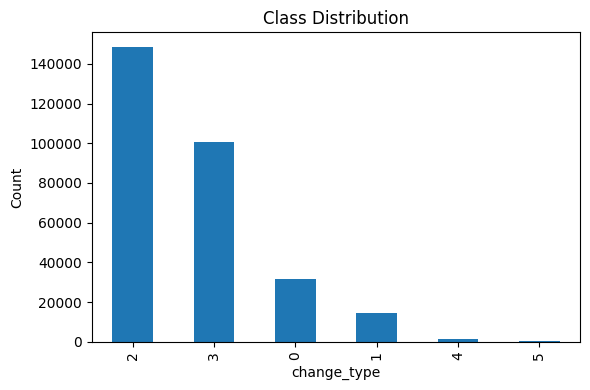

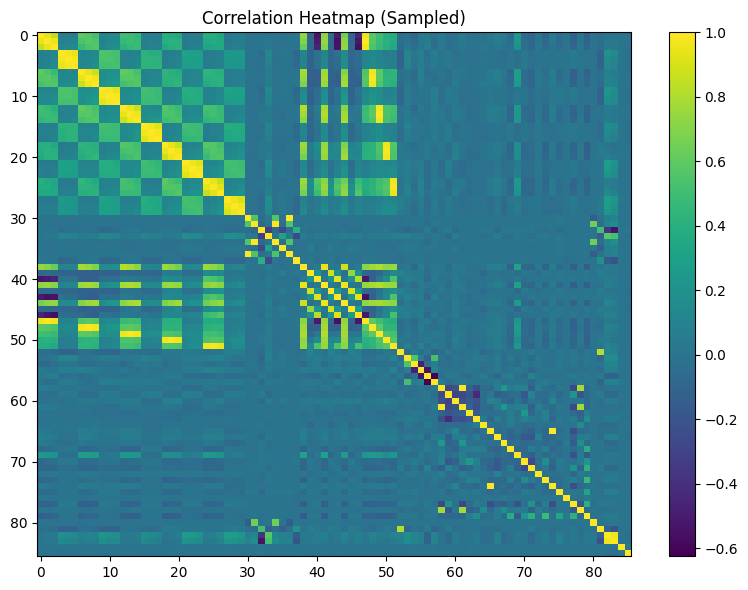

In [ ]:
# ---------- 1) Basic Info ----------
print("Shape:", X_train.shape)
print("\nColumn types:")
print(X_train.dtypes.value_counts())

# ---------- 2) Class Distribution ----------
print("\nClass distribution:")
print(y_train.value_counts())
print("\nClass percentage:")
print(y_train.value_counts(normalize=True) * 100)

plt.figure(figsize=(6,4))
y_train.value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print()
# ---------- 3) Correlation (sampled for speed) ----------
sample = X_train.sample(n=30000, random_state=42)
corr = sample.corr(numeric_only=True)

plt.figure(figsize=(8,6))
plt.imshow(corr.to_numpy(), aspect="auto")
plt.title("Correlation Heatmap (Sampled)")
plt.colorbar()
plt.tight_layout()
plt.show()

For class imbalance we will use weights, and slight augmentation.

In [ ]:
def resample_fold(X_tr, y_tr, seed=42,
                  cap_major={2:50000, 3:50000},
                  up_minor={4:5000, 5:2000}):
    rng = np.random.default_rng(seed)
    y_tr = pd.Series(y_tr)

    idx_parts = []

    # 1) undersample majority classes
    for cls, cap in cap_major.items():
        idx = y_tr.index[y_tr == cls].to_numpy()
        if len(idx) > cap:
            idx = rng.choice(idx, size=cap, replace=False)
        idx_parts.append(idx)

    # 2) keep all other classes by default
    for cls in sorted(y_tr.unique()):
        if cls in cap_major or cls in up_minor:
            continue
        idx_parts.append(y_tr.index[y_tr == cls].to_numpy())

    # 3) oversample rare classes (bootstrap)
    for cls, target in up_minor.items():
        idx = y_tr.index[y_tr == cls].to_numpy()
        if len(idx) == 0:
            continue
        if len(idx) < target:
            idx = rng.choice(idx, size=target, replace=True)
        idx_parts.append(idx)

    new_idx = np.concatenate(idx_parts)
    rng.shuffle(new_idx)

    return X_tr.loc[new_idx], y_tr.loc[new_idx].to_numpy()


# Model selection and model training

## Training

In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report

# --------- resampling (define once) ----------
def resample_fold(X_tr, y_tr, seed=42,
                  cap_major={2:60000, 3:60000},
                  up_minor={4:5000, 5:2000}):

    rng = np.random.default_rng(seed)
    y_tr = pd.Series(y_tr, index=X_tr.index)

    idx_parts = []

    # undersample major classes
    for cls, cap in cap_major.items():
        idx = y_tr[y_tr == cls].index.to_numpy()
        if len(idx) > cap:
            idx = rng.choice(idx, size=cap, replace=False)
        idx_parts.append(idx)

    # keep other classes as-is (0,1)
    for cls in sorted(y_tr.unique()):
        if cls in cap_major or cls in up_minor:
            continue
        idx_parts.append(y_tr[y_tr == cls].index.to_numpy())

    # oversample rare classes
    for cls, target in up_minor.items():
        idx = y_tr[y_tr == cls].index.to_numpy()
        if len(idx) == 0:
            continue
        if len(idx) < target:
            idx = rng.choice(idx, size=target, replace=True)
        idx_parts.append(idx)

    new_idx = np.concatenate(idx_parts)
    rng.shuffle(new_idx)

    return X_tr.loc[new_idx], y_tr.loc[new_idx].values


# --------- prep ----------
y_train = np.asarray(y_train).ravel()

bool_cols = X_train_df.select_dtypes(include=["bool"]).columns
X_train_df = X_train_df.copy()
X_train_df[bool_cols] = X_train_df[bool_cols].astype(np.int8)

classes = np.array([0,1,2,3,4,5])
w = compute_class_weight("balanced", classes=classes, y=y_train)
class_w = dict(zip(classes, w))
class_w[4] *= 5
class_w[5] *= 20

model = lgb.LGBMClassifier(
    objective="multiclassova",
    num_class=6,
    class_weight=class_w,
    n_estimators=800, #2000,
    learning_rate=0.03,
    num_leaves=127,
    min_child_samples=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    force_col_wise=True,
    verbosity=-1
)

X = X_train_df
y = y_train

# --------- single fold ----------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, val_idx = next(skf.split(X, y))

X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
y_tr, y_val = y[tr_idx], y[val_idx]

# resample only training fold
X_tr_rs, y_tr_rs = resample_fold(X_tr, y_tr, seed=42)

print("Before resample:\n", pd.Series(y_tr).value_counts().sort_index())
print("After resample:\n", pd.Series(y_tr_rs).value_counts().sort_index())

model.fit(X_tr_rs, y_tr_rs)
pred = model.predict(X_val)

print("Fold Macro F1:", f1_score(y_val, pred, average="macro"))
print(classification_report(y_val, pred))
print("Pred counts:\n", pd.Series(pred).value_counts().sort_index())

Before resample:
 0     25207
1     11444
2    118748
3     80337
4      1060
5       120
Name: count, dtype: int64
After resample:
 0    25207
1    11444
2    60000
3    60000
4     5000
5     2000
Name: count, dtype: int64
Fold Macro F1: 0.5405562872504583
              precision    recall  f1-score   support

           0       0.71      0.92      0.80      6302
           1       0.61      0.85      0.71      2861
           2       0.84      0.67      0.74     29687
           3       0.63      0.73      0.68     20085
           4       0.20      0.39      0.26       264
           5       0.08      0.03      0.05        31

    accuracy                           0.72     59230
   macro avg       0.51      0.60      0.54     59230
weighted avg       0.74      0.72      0.72     59230

Pred counts:
 0     8149
1     3979
2    23419
3    23148
4      523
5       12
Name: count, dtype: int64


We can clearly see that the model is poorly performing on classes 4 and 5, partially because they are very undersampled, but mainly because the separability on those classes is bad, which suggests we can try some other feature engineering which may allow us to improve the model's performance. Also another possible approach would be to try a different model such as a RandomForest classifier. The next part explores this possibility.

# Fixing Strategy

Let's first define some methods that will be useful to us.

In [ ]:
def parse_date(date_str):
    if pd.isna(date_str) or date_str is None:
        return None
    try:
        return pd.to_datetime(date_str, format='%d-%m-%Y')
    except (ValueError, TypeError):
        return None

def calculate_mean_date(dates):
    dates_series = pd.Series(dates)
    valid_dates = dates_series[dates_series.notna()]

    if len(valid_dates) == 0:
        return pd.Timestamp('2020-01-01')

    mean_date = pd.Timestamp(valid_dates.mean())
    return mean_date

def optimize_array(arr):
    """Optimize memory size of numpy array"""
    if arr.dtype == np.float64:
        return arr.astype(np.float32)
    return arr

def parse_date(date_str):
    return datetime.strptime(date_str, '%d-%m-%Y')

In [ ]:
train_df['change_type']

,change_type
0,1
1,1
2,1
3,1
4,0
...,...
296141,3
296142,2
296143,2
296144,2


In [ ]:
# A weak treatment for missing values is dropping them, this could cause bias but may be less harmful in our tree based models, so let's try first doing this
train_df = train_df.dropna(axis=0, how='any')

# We'll also seperate the y variable
train_y = train_df['change_type']

The logic won't be exactly the same for the test data because we need it for out model's output

In [ ]:
# Get all date columns
DATE_COLUMNS = ["date0", "date1", "date2", "date3", "date4"]

# Convert all date columns to datetime format
for col in DATE_COLUMNS:
    test_df[col] = pd.to_datetime(test_df[col], format='%d-%m-%Y', errors='coerce')

# Calculate mean of valid dates across all date columns
valid_dates = []
for col in DATE_COLUMNS:
    valid_dates.extend(test_df[col].dropna())

mean_date = calculate_mean_date(valid_dates)

# Fill missing values with computed mean date
for col in DATE_COLUMNS:
    test_df[col] = test_df[col].fillna(mean_date)
    test_df[col] = test_df[col].dt.strftime('%d-%m-%Y')

test_df = test_df.fillna(0)

In [ ]:
SELECTED_COLUMNS = [
    "date0", "change_status_date0",
    "img_red_mean_date1", "img_blue_mean_date1", "img_green_mean_date1",
    "date1", "change_status_date1",
    "img_red_mean_date2", "img_blue_mean_date2", "img_green_mean_date2",
    "date2", "change_status_date2",
    "img_red_mean_date3", "img_blue_mean_date3", "img_green_mean_date3",
    "date3", "change_status_date3",
    "img_red_mean_date4", "img_blue_mean_date4", "img_green_mean_date4",
    "date4", "change_status_date4",
    "img_red_mean_date5", "img_blue_mean_date5", "img_green_mean_date5"
]

train_temporal_raw = train_df[SELECTED_COLUMNS].values.reshape(-1, len(SELECTED_COLUMNS))

train_chronological_data = []
for data_point in train_temporal_raw:
    parsed_data = [(parse_date(data_point[i]), data_point[i+1], data_point[i+2], data_point[i+3], data_point[i+4])
                   for i in range(0, len(data_point), 5)]
    sorted_data = sorted(parsed_data, key=lambda x: x[0])
    train_chronological_data.append(sorted_data)

# Extract and organize RGB values for training data
train_rgb_values_r = [point[i][2] for point in train_chronological_data for i in range(5)]
train_rgb_values_b = [point[i][3] for point in train_chronological_data for i in range(5)]
train_rgb_values_g = [point[i][4] for point in train_chronological_data for i in range(5)]

train_rgb_matrix_r = optimize_array(np.array(train_rgb_values_r).reshape(-1, 5))
train_rgb_matrix_b = optimize_array(np.array(train_rgb_values_b).reshape(-1, 5))
train_rgb_matrix_g = optimize_array(np.array(train_rgb_values_g).reshape(-1, 5))

# Compute temporal gaps (days between consecutive dates) for training data
train_temporal_gaps = [(point[i+1][0]-point[i][0]).days for point in train_chronological_data for i in range(4)]
train_temporal_matrix = optimize_array(np.array(train_temporal_gaps).reshape(-1, 4))

# Extract and process evolution/status values for training data
train_evolution_data = []
for data_point in train_chronological_data:
    for i in range(5):
        # Convert to float, default to 0.0 if conversion fails
        value = data_point[i][1]
        try:
            value = float(value)
        except (ValueError, TypeError):
            value = 0.0
        train_evolution_data.append(value)

train_evolution_matrix = np.array(train_evolution_data, dtype=np.float32)
train_evolution_matrix = train_evolution_matrix.reshape(-1, 5)

In [ ]:
train_status_sum = []
for data_point in train_evolution_matrix:
    train_status_sum.append(float(np.sum(data_point)))

evolution_encoder = LabelBinarizer()
train_evolution_one_hot = optimize_array(evolution_encoder.fit_transform(train_status_sum))

# Extract area and length features from training data geometry
train_area_features = optimize_array(np.asarray(train_df[['geometry']].area).reshape(-1, 1))
train_length_features = optimize_array(np.asarray(train_df[['geometry']].length).reshape(-1, 1))

urban_encoder = LabelBinarizer()
geography_encoder = LabelBinarizer()

# Encode urban type and geography type for training data
train_urban_values = train_df['urban_type']
train_urban_encoded = optimize_array(urban_encoder.fit_transform(train_urban_values))
train_urban_encoded = train_urban_encoded.reshape(-1, len(urban_encoder.classes_))

train_geography_values = train_df['geography_type']
train_geography_encoded = optimize_array(geography_encoder.fit_transform(train_geography_values))
train_geography_encoded = train_geography_encoded.reshape(-1, len(geography_encoder.classes_))

# Progressive concatenation of training features
train_feature_matrix = np.hstack((train_area_features, train_length_features))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_urban_encoded))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_geography_encoded))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_temporal_matrix))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_evolution_one_hot))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_rgb_matrix_r))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_rgb_matrix_b))
gc.collect()
train_feature_matrix = np.hstack((train_feature_matrix, train_rgb_matrix_g))
gc.collect()

/tmp/ipython-input-309572049.py:9: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  train_area_features = optimize_array(np.asarray(train_df[['geometry']].area).reshape(-1, 1))
/tmp/ipython-input-309572049.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  train_length_features = optimize_array(np.asarray(train_df[['geometry']].length).reshape(-1, 1))


0

In [ ]:
# Process test data features
test_area_features = optimize_array(np.asarray(test_df[['geometry']].area).reshape(-1, 1))
test_length_features = optimize_array(np.asarray(test_df[['geometry']].length).reshape(-1, 1))

test_urban_values = test_df['urban_type']
test_urban_encoded = optimize_array(urban_encoder.transform(test_urban_values))
test_urban_encoded = test_urban_encoded.reshape(-1, len(urban_encoder.classes_))

test_geography_values = test_df['geography_type']
test_geography_encoded = optimize_array(geography_encoder.transform(test_geography_values))
test_geography_encoded = test_geography_encoded.reshape(-1, len(geography_encoder.classes_))

test_temporal_raw = test_df[SELECTED_COLUMNS].values.reshape(-1, len(SELECTED_COLUMNS))

test_chronological_data = []
for data_point in test_temporal_raw:
    parsed_data = [(parse_date(data_point[i]), data_point[i+1], data_point[i+2], data_point[i+3], data_point[i+4])
                   for i in range(0, len(data_point), 5)]
    sorted_data = sorted(parsed_data, key=lambda x: x[0])
    test_chronological_data.append(sorted_data)

# Extract and organize RGB values for test data
test_rgb_values_r = [point[i][2] for point in test_chronological_data for i in range(5)]
test_rgb_values_b = [point[i][3] for point in test_chronological_data for i in range(5)]
test_rgb_values_g = [point[i][4] for point in test_chronological_data for i in range(5)]

test_rgb_matrix_r = optimize_array(np.array(test_rgb_values_r).reshape(-1, 5))
test_rgb_matrix_b = optimize_array(np.array(test_rgb_values_b).reshape(-1, 5))
test_rgb_matrix_g = optimize_array(np.array(test_rgb_values_g).reshape(-1, 5))

# Compute temporal gaps for test data
test_temporal_gaps = [(point[i+1][0]-point[i][0]).days for point in test_chronological_data for i in range(4)]
test_temporal_matrix = optimize_array(np.array(test_temporal_gaps).reshape(-1, 4))

# Extract and process evolution/status values for test data
test_evolution_data = []
for data_point in test_chronological_data:
    for i in range(5):
        value = data_point[i][1]
        try:
            value = float(value)
        except (ValueError, TypeError):
            value = 0.0
        test_evolution_data.append(value)

test_evolution_matrix = np.array(test_evolution_data, dtype=np.float32)
test_evolution_matrix = test_evolution_matrix.reshape(-1, 5)

test_status_sum = []
for data_point in test_evolution_matrix:
    test_status_sum.append(float(np.sum(data_point)))

test_evolution_one_hot = optimize_array(evolution_encoder.transform(test_status_sum))

# Progressive concatenation of test features
test_feature_matrix = np.hstack((test_area_features, test_length_features))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_urban_encoded))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_geography_encoded))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_temporal_matrix))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_evolution_one_hot))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_rgb_matrix_r))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_rgb_matrix_b))
gc.collect()
test_feature_matrix = np.hstack((test_feature_matrix, test_rgb_matrix_g))
gc.collect()

/tmp/ipython-input-720193585.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  test_area_features = optimize_array(np.asarray(test_df[['geometry']].area).reshape(-1, 1))
/tmp/ipython-input-720193585.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  test_length_features = optimize_array(np.asarray(test_df[['geometry']].length).reshape(-1, 1))


0

In [ ]:
np.save("array.npy", train_feature_matrix)

In [ ]:
train_y.to_csv('train_y.csv', index=False)

In [ ]:
np.save("testarray.npy", test_feature_matrix)

In [ ]:
# Split data for validation and training
X_train, X_val, y_train, y_val = train_test_split(train_feature_matrix, train_y, test_size=0.2, random_state=60)

# Create and train random forest classifier
random_forest_model = RandomForestClassifier(n_estimators=300, random_state=50)
random_forest_model.fit(train_feature_matrix, train_y)

# Evaluate model on validation set
validation_predictions = random_forest_model.predict(X_val)
accuracy = accuracy_score(y_val, validation_predictions)
print(f"Validation Accuracy: {accuracy:.2f}")

# Generate predictions on test set
test_predictions = random_forest_model.predict(test_feature_matrix)

In [ ]:
# Save predictions to submission file
submission_dataframe = pd.DataFrame(test_predictions, columns=['change_type'])
submission_dataframe.to_csv("Sample_submission.csv", index=True, index_label='Id')
print('Done saving')